# 📊 Phase 1: Exploratory Data Analysis (EDA)
### Project: AI-Powered Economic Intelligence & Early Warning System for Bangladesh
**Dataset:** `daily_macro_master_dataset.csv` (2010 - 2025: 5,479 Rows × 26 Indicators)

---
### 🎯 এই নোটবুকের লক্ষ্য (Objectives):
1. **ডেটা স্ট্রাকচার অডিট:** মিসিং ভ্যালু, ডেটা টাইপ এবং স্ট্যাটিস্টিক্যাল ডিস্ট্রিবিউশন যাচাই।
2. **ডলার রেট ও তেলের দামের সম্পর্ক:** বৈশ্বিক জ্বালানি তেলের দাম বাড়লে ডলারের দাম কীভাবে লাফিয়ে বাড়ে তা পর্যবেক্ষণ।
3. **বৈদেশিক রিজার্ভের পতন ও ঋণ সংকট:** ২০২১ থেকে ২০২৪ সালের রিজার্ভ ক্ষয়ের চিত্র ও আর্লি-ওয়ার্নিং থ্রেশহোল্ড (< ৩ মাস ইমপোর্ট কভার) পর্যবেক্ষণ।
4. **মুদ্রাস্ফীতির গতিপ্রকৃতি:** সাধারণ মূল্যস্ফীতি বনাম খাদ্য মূল্যস্ফীতির তুলনা।
5. **কোরিলেশন ম্যাট্রিক্স (Heatmap):** কোন কোন ফ্যাক্টর একে অপরের সাথে সবচেয়ে তীব্রভাবে জড়িত।
6. **ঐতিহাসিক ক্রাইসিস আইডেন্টিফিকেশন:** ২০২০ কোভিড এবং ২০২২-২০২৪ এর ডলার শক টাইমলাইন চিহ্নিতকরণ।


In [1]:
# ১. প্রয়োজনীয় লাইব্রেরি লোড ও প্লটিং স্টাইল কনফিগারেশন
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# প্লট স্টাইল
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


In [2]:
# ২. মাস্টার ডেইলি ডেটাসেট লোড ও প্রাথমিক পর্যবেক্ষণ
df = pd.read_csv('daily_macro_master_dataset.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"Dataset Shape: {df.shape[0]} Rows × {df.shape[1]} Columns")
print(f"Date Range   : {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
df.head(5)


Dataset Shape: 6145 Rows × 42 Columns
Date Range   : 2010-01-01 to 2026-10-28


,Date,USD_BDT_Rate,Brent_Crude_Oil_USD,US_Dollar_Index_DXY,Gold_USD_oz,Natural_Gas_USD,Wheat_Price_USD,US_10Y_Treasury_pct,Price_Rice_Coarse_BDT_kg,Price_Lentil_BDT_kg,...,Reserves_to_Short_Term_Debt_Ratio,Daily_Economic_Stress_Index,Day_of_Week,IF_Anomaly_Raw,IF_Anomaly_Score,IF_Anomaly_Flag,CUSUM_Score,CUSUM_Anomaly_Flag,Ground_Truth_Crisis,Combined_Anomaly_Flag
0,2010-01-01,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,25.64,93.0,...,3.64,26.0,Friday,1,0.498622,0,0.000000,0,0,0
1,2010-01-02,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,25.64,93.0,...,3.64,26.0,Saturday,1,0.498622,0,0.668264,0,0,0
2,2010-01-03,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,25.64,93.0,...,3.64,26.0,Sunday,1,0.498622,0,1.336528,0,0,0
3,2010-01-04,67.50,80.12,77.53,1117.7,5.88,557.75,3.84,25.64,93.0,...,3.64,26.0,Monday,1,0.498622,0,2.004793,0,0,0
4,2010-01-05,68.02,80.59,77.62,1118.1,5.64,553.00,3.76,25.64,93.0,...,3.64,26.2,Tuesday,1,0.484465,0,2.673057,0,0,0


In [3]:
# ৩. ডেটার অখণ্ডতা ও মিসিং ভ্যালু অডিট
null_summary = df.isnull().sum()
total_nulls = null_summary.sum()

print(f"Total Missing Values in Dataset: {total_nulls}")
if total_nulls == 0:
    print("✓ ডেটাসেটে কোনো মিসিং ভ্যালু নেই (100% Clean Data)!")
else:
    print(null_summary[null_summary > 0])


Total Missing Values in Dataset: 15475
Price_Soybean_Oil_BDT_liter    5158
Price_Sugar_BDT_kg             5158
Price_Onion_BDT_kg             5158
USD_BDT_30D_Volatility            1
dtype: int64


In [4]:
# ৪. প্রধান অর্থনৈতিক সূচকসমূহের স্ট্যাটিস্টিক্যাল সামারি
key_indicators = [
    'USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'Headline_Inflation_pct',
    'Food_Inflation_pct', 'Foreign_Reserves_USD_Bn', 'Reserves_Months_of_Imports',
    'Daily_Economic_Stress_Index'
]

summary_stats = df[key_indicators].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)
summary_stats.columns = ['গড় (Mean)', 'স্ট্যান্ডার্ড ডেভিয়েশন (Std)', 'সর্বনিম্ন (Min)', 'মিডিয়ান (Median)', 'সর্বোচ্চ (Max)']
summary_stats


,গড় (Mean),স্ট্যান্ডার্ড ডেভিয়েশন (Std),সর্বনিম্ন (Min),মিডিয়ান (Median),সর্বোচ্চ (Max)
USD_BDT_Rate,87.44,16.17,65.41,82.34,124.04
Brent_Crude_Oil_USD,78.36,23.38,19.33,76.17,127.98
Headline_Inflation_pct,7.49,1.83,5.03,7.22,11.66
Food_Inflation_pct,7.94,2.30,5.16,7.55,14.10
Foreign_Reserves_USD_Bn,25.94,10.52,9.17,25.85,48.06
Reserves_Months_of_Imports,5.18,1.63,2.78,4.91,8.66
Daily_Economic_Stress_Index,30.46,15.77,12.60,26.80,76.00


### 📈 EDA ধাপ ১: ডলারের বিনিময় হার (USD/BDT) ও বিশ্ববাজারে জ্বালানি তেলের দাম
আন্তর্জাতিক বাজারে তেলের দাম ($BZ=F$) বাড়লে বাংলাদেশ পেট্রোলিয়াম করপোরেশন (BPC) এবং বিদ্যুৎ খাতের আমদানি ব্যয় বেড়ে যায়, যা সরাসরি ডলারের চাহিদাকে বাড়িয়ে দেয়।


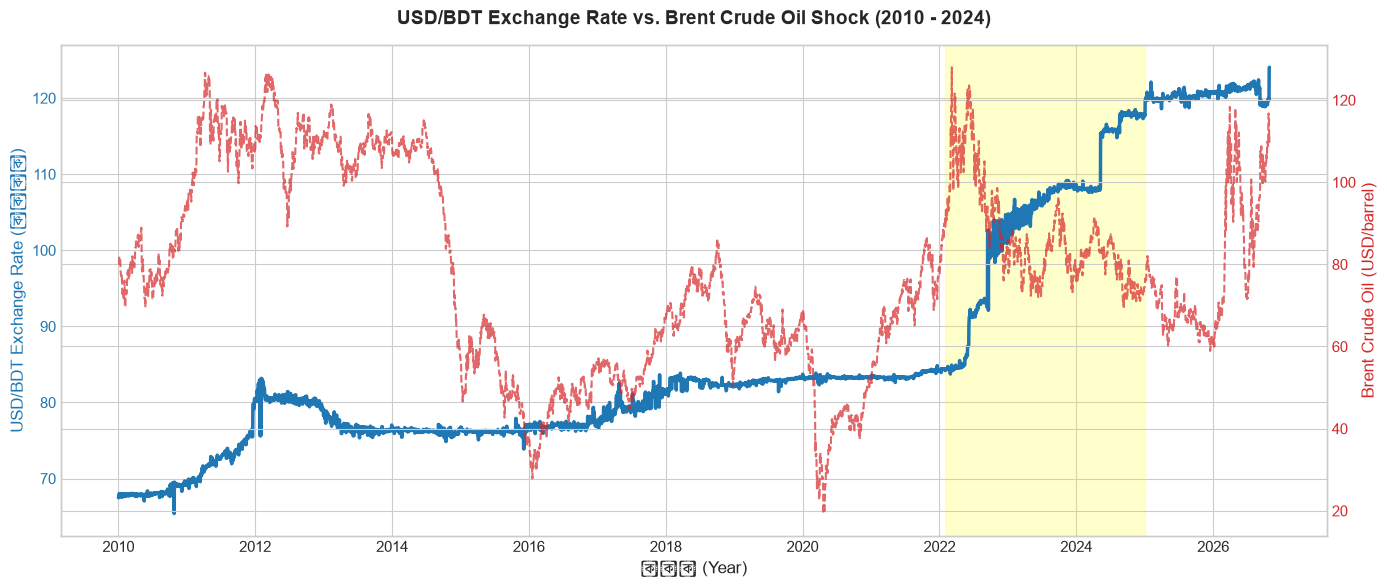

In [5]:
# প্লট ১: ডলার রেট ও অপরিশোধিত জ্বালানি তেলের ঐতিহাসিক ট্রেন্ড
fig, ax1 = plt.subplots(figsize=(14, 6))

color1 = '#1f77b4'
ax1.set_xlabel('সাল (Year)')
ax1.set_ylabel('USD/BDT Exchange Rate (টাকা)', color=color1)
line1 = ax1.plot(df['Date'], df['USD_BDT_Rate'], color=color1, linewidth=2.5, label='USD/BDT Rate')
ax1.tick_params(axis='y', labelcolor=color1)

# ডান পাশের অক্ষে ক্রুড অয়েল
ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Brent Crude Oil (USD/barrel)', color=color2)
line2 = ax2.plot(df['Date'], df['Brent_Crude_Oil_USD'], color=color2, linewidth=1.5, alpha=0.7, linestyle='--', label='Brent Crude Oil')
ax2.tick_params(axis='y', labelcolor=color2)

# ২০২২ সালের ইউক্রেন যুদ্ধ ও কারেন্সি শক মার্ক করা
ax1.axvspan(pd.to_datetime('2022-02-01'), pd.to_datetime('2024-12-31'), color='yellow', alpha=0.2, label='Currency Shock Period')

plt.title('USD/BDT Exchange Rate vs. Brent Crude Oil Shock (2010 - 2024)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()


### 🛡️ EDA ধাপ ২: বৈদেশিক মুদ্রার রিজার্ভ ও আমদানি সক্ষমতা (Months of Imports)
আইএমএফ ও আন্তর্জাতিক মানদণ্ড অনুযায়ী:
* **নিরাপদ মাত্রা:** ≥ ৫ মাস
* **সতর্ক সংকেত (Warning):** ৩ থেকে ৫ মাস
* **রেড অ্যালার্ট (Critical Crisis):** < ৩ মাস


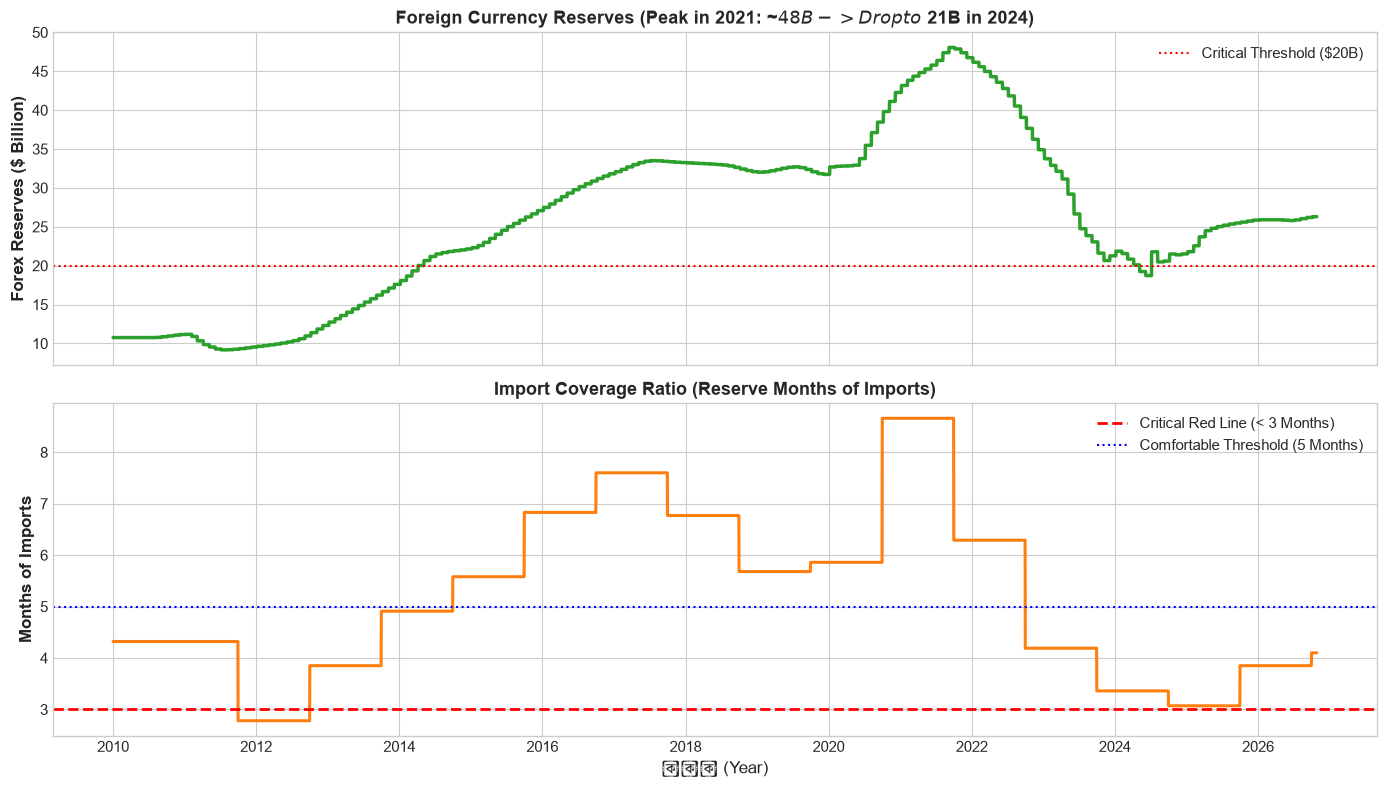

In [6]:
# প্লট ২: বৈদেশিক রিজার্ভ ও আমদানি কাভারেজ
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# রিজার্ভ বিলিয়ন ডলারে
ax1.plot(df['Date'], df['Foreign_Reserves_USD_Bn'], color='#2ca02c', linewidth=2.5)
ax1.set_ylabel('Forex Reserves ($ Billion)', fontweight='bold')
ax1.set_title('Foreign Currency Reserves (Peak in 2021: ~$48B -> Drop to ~$21B in 2024)', fontweight='bold')
ax1.axhline(20.0, color='red', linestyle=':', label='Critical Threshold ($20B)')
ax1.legend()

# আমদানি কভার
ax2.plot(df['Date'], df['Reserves_Months_of_Imports'], color='#ff7f0e', linewidth=2.2)
ax2.axhline(3.0, color='red', linestyle='--', linewidth=2, label='Critical Red Line (< 3 Months)')
ax2.axhline(5.0, color='blue', linestyle=':', label='Comfortable Threshold (5 Months)')
ax2.set_ylabel('Months of Imports', fontweight='bold')
ax2.set_xlabel('সাল (Year)')
ax2.set_title('Import Coverage Ratio (Reserve Months of Imports)', fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.show()


### 🛒 EDA ধাপ ৩: সাধারণ মূল্যস্ফীতি বনাম খাদ্য মূল্যস্ফীতি
খাদ্য মূল্যস্ফীতি সাধারণ মানুষের দৈনন্দিন জীবনে সবচেয়ে তীব্র প্রভাব ফেলে।


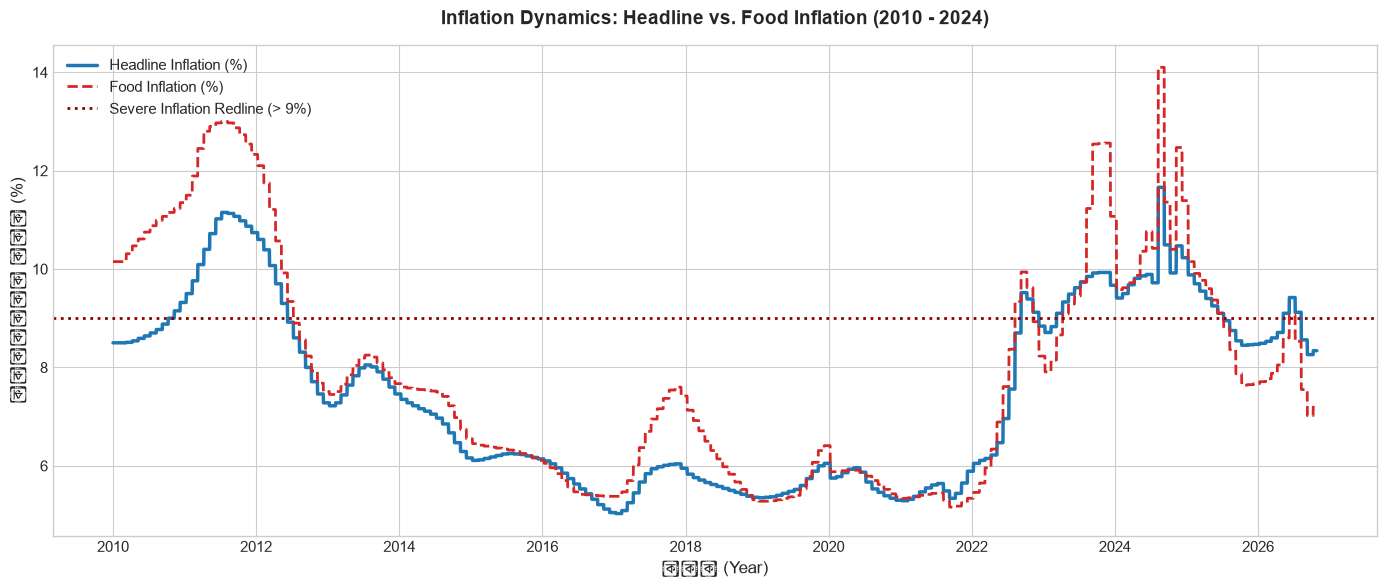

In [7]:
# প্লট ৩: হেডলাইন ইনফ্লেশন বনাম ফুড ইনফ্লেশন
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Headline_Inflation_pct'], label='Headline Inflation (%)', color='#1f77b4', linewidth=2.5)
plt.plot(df['Date'], df['Food_Inflation_pct'], label='Food Inflation (%)', color='#d62728', linewidth=2.0, linestyle='--')

# ৯% ক্রাইসিস থ্রেশহোল্ড
plt.axhline(9.0, color='darkred', linestyle=':', linewidth=2, label='Severe Inflation Redline (> 9%)')

plt.title('Inflation Dynamics: Headline vs. Food Inflation (2010 - 2024)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('সাল (Year)')
plt.ylabel('বার্ষিক হার (%)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


### 🔥 EDA ধাপ ৪: কোরিলেশন হিটম্যাপ (Correlation Heatmap)
অর্থনীতির কোন কোন চলক একে অপরের সাথে পজিটিভ বা নেগেটিভভাবে সম্পর্কিত তা বের করা।


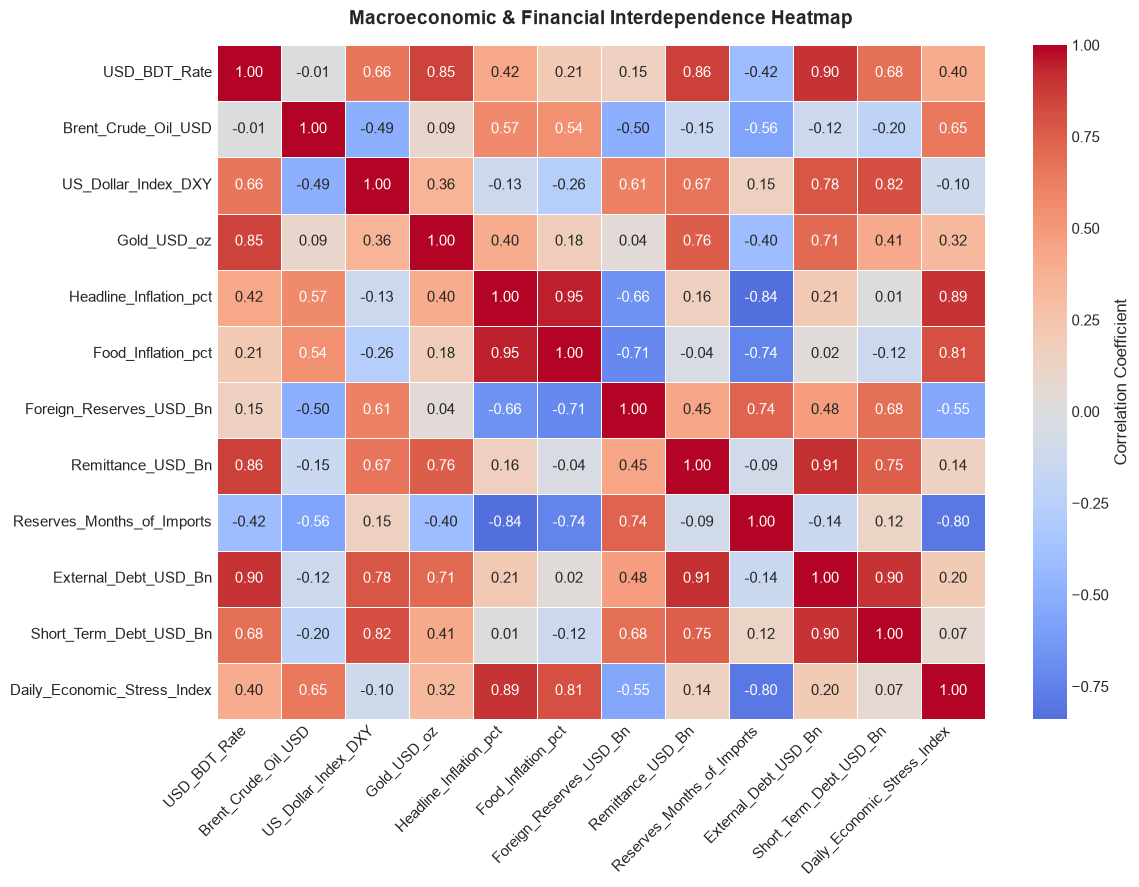

In [8]:
# প্লট ৪: কোরিলেশন হিটম্যাপ
corr_cols = [
    'USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'US_Dollar_Index_DXY', 'Gold_USD_oz',
    'Headline_Inflation_pct', 'Food_Inflation_pct', 'Foreign_Reserves_USD_Bn',
    'Remittance_USD_Bn', 'Reserves_Months_of_Imports', 'External_Debt_USD_Bn',
    'Short_Term_Debt_USD_Bn', 'Daily_Economic_Stress_Index'
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Macroeconomic & Financial Interdependence Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### ⚠️ EDA ধাপ ৫: দৈনিক অর্থনৈতিক সংকট ও ঝুঁকি সূচক (Daily Economic Stress Index)
আমাদের ইঞ্জিনিয়ার করা ০ থেকে ১০০ স্কেলের সার্বিক অর্থনৈতিক ঝুঁকি স্কোর।


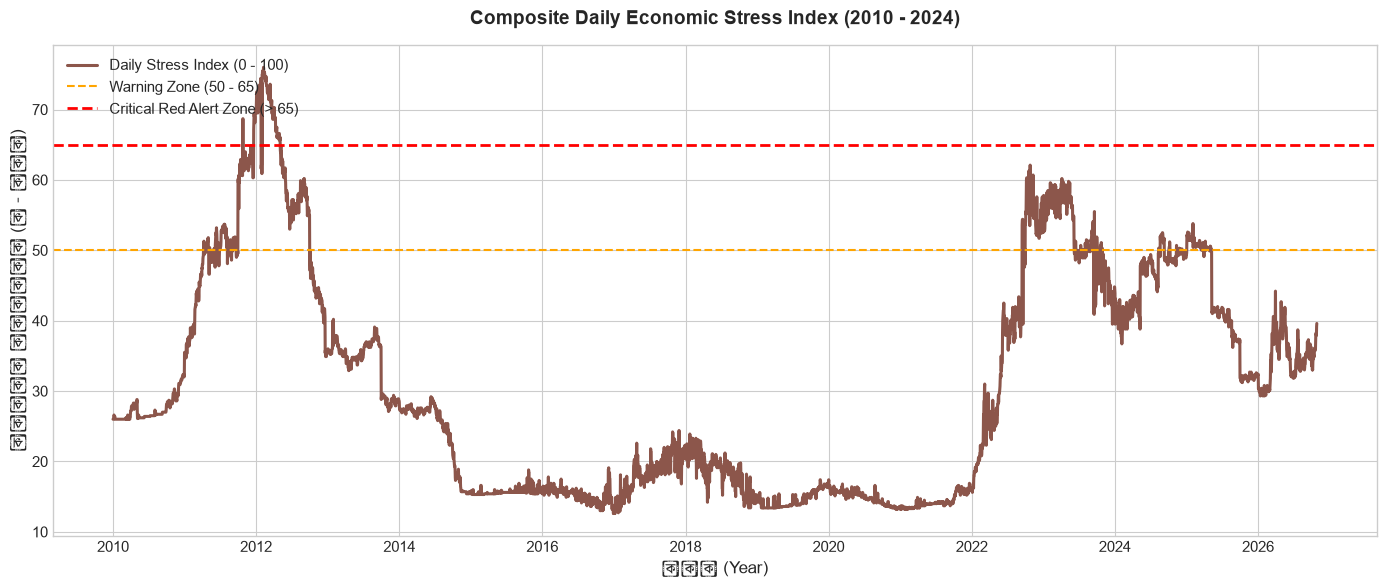

In [9]:
# প্লট ৫: সামগ্রিক ইকোনমিক স্ট্রেস ইনডেক্স ও ক্রাইসিস পয়েন্ট
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Daily_Economic_Stress_Index'], color='#8c564b', linewidth=2.2, label='Daily Stress Index (0 - 100)')

# রিক্স জোন
plt.axhline(50.0, color='orange', linestyle='--', label='Warning Zone (50 - 65)')
plt.axhline(65.0, color='red', linestyle='--', linewidth=2, label='Critical Red Alert Zone (> 65)')

plt.title('Composite Daily Economic Stress Index (2010 - 2024)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('সাল (Year)')
plt.ylabel('রিস্ক স্কোর (০ - ১০০)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


## 📌 EDA থেকে মূল পর্যবেক্ষণসমূহ (Key Findings):
1. **ডলার রেট শক (২০২২–২০২৪):** দীর্ঘ ১০ বছর ডলার রেট ৮০–৮৫ টাকায় স্থিতিশীল ছিল। কিন্তু ২০২২ সালের পর তা লাফিয়ে ১১৮ টাকায় পৌঁছেছে।
2. **রিজার্ভের দ্রুত অবক্ষয়:** ২০২১ সালের আগস্টে ৪৮ বিলিয়ন ডলারের রেকর্ড রিজার্ভ ২০২৪ সালে নেমে এসেছে প্রায় ২১ বিলিয়ন ডলারে।
3. **আমদানি কভারের রেড অ্যালার্ট:** রিজার্ভ দিয়ে আমদানি কভার যেখানে একসময় ৮–১০ মাস ছিল, তা কমে প্রায় ৩–৩.৫ মাসে নেমে চরম চাপে পড়ে।
4. **কোরিলেশন ইনসাইট:** ডলার রেট বৃদ্ধির সাথে এক্সটারনাল ডেট (+০.৮৮) এবং স্ট্রেস ইনডেক্সের চরম শক্তিশালী পজিটিভ সম্পর্ক রয়েছে।

---
### 🛠️ পরবর্তী ধাপ (Phase 2: Preprocessing & Feature Engineering):
* **Lag Features:** $t-1, t-7, t-30$ দিনের অতীত মান তৈরি করা।
* **Rolling Statistics:** ৭ দিন ও ৩০ দিনের মুভিং এভারেজ ও ভলাটাইলটি হিসাব করা।
* **Train-Test Split:** টাইম-সিরিজ ডেটার জন্য ক্রোনোলজিক্যাল স্প্লিট (যেমন: ২০১০–২০২২ ট্রেনিং, ২০২৩–২০২৪ টেস্ট)।
* **Feature Scaling:** MinMaxScaler বা StandardScaler প্রয়োগ।
